# Detecció de keypoints

Notebook mínim per carregar les imatges de consulta, seleccionar-ne una, executar un detector i visualitzar els keypoints.

La variable `keypoints` queda disponible al final per poder-hi afegir després el càlcul de descriptors, per exemple amb SIFT.

In [104]:
from pathlib import Path
import sys
import cv2
import matplotlib.pyplot as plt

from utils import load_images
from keypoints import detect, anms

## Carregar les imatges

Ajusta `PROJECT_ROOT` si el notebook no es troba dins d'una carpeta `notebooks/` situada a l'arrel del projecte.

In [105]:
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
QSD1_DIR = DATA_DIR / "qsd1_w4"

db_ids, db_images = load_images(DATA_DIR / "BBDD")
query_ids, query_images = load_images(QSD1_DIR)



## Seleccionar imatge, detector i paràmetres

Modifica `IMAGE_INDEX` i `METHOD`. Els paràmetres de cada detector estan agrupats a `PARAMS`; pots modificar-los o deixar els valors per defecte.

Els mètodes disponibles són `dog`, `harris_laplace` i `hybrid`.

In [106]:
IMAGE_INDEX = 6
METHOD = "hybrid"
MAX_KPS = 500
CLAHE = False

PARAMS = {
    "dog": {
        "contrast": 0.04,
        "edge": 10,
        "sigma": 1.6,
    },
    "harris_laplace": {
        "n_scales": 8,
        "sigma0": 1.6,
        "k": 1.4,
        "harris_thr": 1e-6,
        "log_thr": 0.01,
        "alpha": 0.04,
    },
    "hybrid": {
        "dog_kw": {"contrast": 0.04, "edge": 10, "sigma": 1.6},
        "hl_kw": {
            "n_scales": 8,
            "sigma0": 1.6,
            "k": 1.4,
            "harris_thr": 1e-6,
            "log_thr": 0.01,
            "alpha": 0.04,
        },
    },
}

## Detectar i visualitzar els keypoints

`keypoints` conté la llista de punts retornada pel detector. La imatge es mostra amb els cercles i les orientacions dels punts.

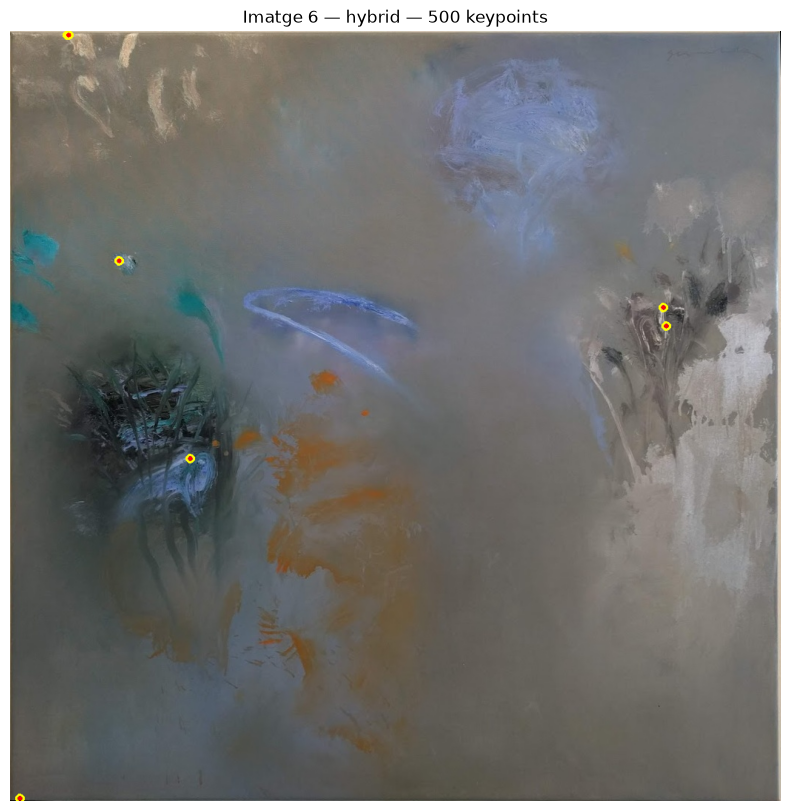

In [107]:
image = db_images[IMAGE_INDEX]

keypoints = detect(
    image,
    method=METHOD,
    max_kps=MAX_KPS,
    clahe=CLAHE,
    **PARAMS[METHOD],
)

image_with_keypoints = image.copy()
n_kp = anms(keypoints, 10)

for kp in n_kp:
    x, y = map(int, kp.pt)
    radius = max(5, int(kp.size / 2))

    cv2.circle(image_with_keypoints, (x, y), radius, (0, 255, 255), 2)
    cv2.circle(image_with_keypoints, (x, y), 3, (0, 0, 255), -1)

plt.figure(figsize=(16, 10))
plt.imshow(cv2.cvtColor(image_with_keypoints, cv2.COLOR_BGR2RGB))
plt.title(f"Imatge {IMAGE_INDEX} — {METHOD} — {len(keypoints)} keypoints")
plt.axis("off")
plt.show()